# SVDD: two rewards, one image, several guidance scales
Same initial noise -> **baseline**, **SVDD steered by aesthetics**, **SVDD steered by compressibility**.
Every image is scored by *both* rewards, so we can see each reward pull the image in its own direction.

In [6]:
# ---- 1. Setup: the authors' repo ships the aesthetic scorer and its MLP checkpoint ----
import os, sys, io, types,time, pathlib, subprocess, itertools
REPO = pathlib.Path("/kaggle/working/SVDD-image")
if not REPO.exists():
    subprocess.run(["git", "clone", "https://github.com/masa-ue/SVDD-image.git", str(REPO)], check=True)
sys.path.insert(0, str(REPO)); os.chdir(REPO)      # scorer loads assets/ relative to the repo
assert (REPO / "assets" / "sac+logos+ava1-l14-linearMSE.pth").exists(), "aesthetic checkpoint missing"

import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from transformers import CLIPProcessor
from aesthetic_scorer import AestheticScorerDiff   # from the repo
DEVICE, DTYPE = "cuda", torch.float16

## 2. Reward functions (a reward = any function: list of PIL images -> 1 float per image; no gradients needed)
**Reward A - aesthetic score** (official SVDD scorer = LAION aesthetic predictor):
image -> CLIP ViT-L/14 image embedding -> L2-normalise -> MLP head (`sac+logos+ava1-l14-linearMSE.pth`,
trained on human ratings of SAC, LAION-logos and AVA) -> scalar (roughly 4-7 for SD images, higher = prettier).
The wrapper uses the matching HF `CLIPProcessor` (resize/crop/normalise), since the scorer expects preprocessed tensors.

**Reward B - compressibility**: minus the JPEG file size in KB. Non-differentiable, rewards flat / simple images.

In [3]:
processor = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")
aes_model = AestheticScorerDiff(dtype=torch.float32).to(DEVICE).eval().requires_grad_(False)

# Compatibility patch: newer `transformers` changed get_image_features, so call vision tower + projection directly
aes_model.clip.get_image_features = types.MethodType(
    lambda self, pixel_values: self.visual_projection(
        self.vision_model(pixel_values=pixel_values, return_dict=True).pooler_output),
    aes_model.clip)

@torch.inference_mode()
def aesthetic_reward(images):                       # list[PIL] -> tensor [len(images)]
    px = processor(images=[im.convert("RGB") for im in images], return_tensors="pt")["pixel_values"].to(DEVICE)
    scores, _ = aes_model(px)                       # official scorer returns (scores, extras)
    return scores.reshape(-1).float().cpu()

def compress_reward(images, quality=90):            # list[PIL] -> tensor [len(images)]
    sizes = []
    for im in images:
        buf = io.BytesIO(); im.save(buf, format="JPEG", quality=quality); sizes.append(-buf.tell() / 1024)
    return torch.tensor(sizes)

# name -> (reward fn, alpha). alpha = softmax temperature in the units of that reward (smaller = greedier)
REWARDS = {"aesthetic": (aesthetic_reward, 0.1), "compress": (compress_reward, 5.0)}
print("sanity:", aesthetic_reward([Image.new("RGB", (512, 512), "skyblue")]).tolist())

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

sanity: [4.417314529418945]


## 3. Stable Diffusion 1.5 + SVDD-PM sampler
Per step: (1) draw N candidates from the pretrained DDIM(eta=1) transition, (2) value = reward(decoded x0_hat),
(3) resample one candidate with prob ~ softmax(value / alpha). `reward=None` gives the plain stochastic baseline.

In [4]:
from diffusers import StableDiffusionPipeline, DDIMScheduler
pipe = StableDiffusionPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5",
                                               torch_dtype=DTYPE, safety_checker=None).to(DEVICE)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
unet, vae, sch = pipe.unet, pipe.vae, pipe.scheduler

@torch.no_grad()
def decode(z):                                       # latents -> list[PIL]
    x = torch.cat([vae.decode(c / vae.config.scaling_factor).sample for c in z.split(2)])
    x = ((x / 2 + 0.5).clamp(0, 1) * 255).round().byte().permute(0, 2, 3, 1).cpu().numpy()
    return [Image.fromarray(a) for a in x]

@torch.no_grad()
def sample(prompt, seed, cfg, reward=None, N=4, steps=25, eta=1.0):
    """Returns (PIL image, mean std of candidate rewards = how much room SVDD had to choose)."""
    cond, uncond = pipe.encode_prompt(prompt, DEVICE, 1, True, negative_prompt="")
    def eps(x, t):                                   # classifier-free-guided noise prediction at scale `cfg`
        emb = torch.cat([uncond.expand(len(x), -1, -1), cond.expand(len(x), -1, -1)])
        eu, ec = unet(torch.cat([x, x]), t, encoder_hidden_states=emb).sample.chunk(2)
        return eu + cfg * (ec - eu)
    sch.set_timesteps(steps, device=DEVICE); ts = sch.timesteps
    gen = torch.Generator(DEVICE).manual_seed(seed)  # same seed -> same x_T for every method (paired comparison)
    x = torch.randn(1, 4, 64, 64, generator=gen, device=DEVICE, dtype=DTYPE)
    spreads = []
    for i, t in enumerate(ts):
        e = eps(x, t)
        if reward is None:                           # baseline: ordinary stochastic step
            x = sch.step(e, t, x, eta=eta, generator=gen).prev_sample; continue
        fn, alpha = reward
        c = sch.step(e.repeat(N, 1, 1, 1), t, x.repeat(N, 1, 1, 1), eta=eta, generator=gen).prev_sample  # (1) N candidates
        if i + 1 < len(ts):                          # (2) x0_hat of each candidate, via the model at the next timestep
            tn = ts[i + 1]; a = sch.alphas_cumprod[int(tn)].to(DEVICE, torch.float32)
            x0 = ((c.float() - (1 - a).sqrt() * eps(c, tn).float()) / a.sqrt()).to(DTYPE)
        else:
            x0 = c
        r = fn(decode(x0)).to(DEVICE); spreads.append(r.std().item())
        x = c[torch.multinomial(torch.softmax(r / alpha, 0), 1, generator=gen).item()][None]  # (3) resample
    return decode(x)[0], (float(np.mean(spreads)) if spreads else float("nan"))

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


## 4. Experiment design
Six compositional prompts; `objects` lists the things each prompt must contain (also used to name the files).
Three CFG scales: SVDD acts on top of CFG; low CFG = diverse proposals, high CFG = concentrated proposals.
Per image we record the **generation time** (`seconds`): for SVDD it includes the N candidates, the extra model pass and the
reward calls at every step, so `x_baseline` in the time table shows how much more SVDD costs than plain sampling.

In [7]:
PROMPTS = [
    {
        "prompt": "a black cat chasing a butterfly in a desert",
        "objects": ["cat", "butterfly"],
        #"token_indices": [2, 5],
    },
    {
        "prompt": "a man and a woman sitting in a cafe",
        "objects": ["man", "woman"],
        #"token_indices": [2, 5],
    },
    {
        "prompt": "a dog and a cat in a garden with flowers",
        "objects": ["dog", "cat", "flowers"],
        #"token_indices": [3,8],
    },
    {
        "prompt": "a black motorcyle and a red car",  
        "objects": ["motorcycle", "car"],
        #"token_indices": [3,8],
    },
    {
        "prompt": "a 19th century ship in an ocean",
        "objects": ["ship"],
        #"token_indices": [3,8],
    },
    {
        "prompt": "a banana and an apple",
        "objects": ["banana", "apple"],
        #"token_indices": [3,8],
    },
]
for e in PROMPTS: e["key"] = "_".join(e["objects"])       # short name used in file names

SCALES, SEEDS, N, STEPS = [7.5], [10, 20, 30, 40, 50], 4, 50   # trim SCALES / SEEDS if the run is too long
METHODS = {"baseline": None, "svdd_aesthetic": REWARDS["aesthetic"], "svdd_compress": REWARDS["compress"]}

RES = pathlib.Path("/kaggle/working/results")             # everything you want to download lives here
for sub in [*(f"images/{m}" for m in METHODS), "tables", "figures"]: (RES / sub).mkdir(parents=True, exist_ok=True)

sample(PROMPTS[0]["prompt"], 0, 7.5, None, N, 2)          # warm-up (CUDA init) so the first timed image is not inflated
rows, imgs = [], {}
for e, g, s in tqdm(list(itertools.product(PROMPTS, SCALES, SEEDS))):
    p, k = e["prompt"], e["key"]
    for m, rw in METHODS.items():
        torch.cuda.synchronize(); t0 = time.time()
        im, spread = sample(p, s, g, rw, N, STEPS)
        torch.cuda.synchronize(); sec = time.time() - t0   # generation time of THIS image (final scoring below is not included)
        imgs[(k, g, s, m)] = im; im.save(RES / "images" / m / f"{k}_cfg{g}_seed{s}.png")
        rows.append(dict(prompt=k, cfg=g, seed=s, method=m, seconds=round(sec, 2), spread=spread,   # score EVERY image with BOTH rewards
                         aesthetic=aesthetic_reward([im]).item(), jpeg_kb=-compress_reward([im]).item()))
    pd.DataFrame(rows).to_csv(RES / "tables" / "results_raw.csv", index=False)   # refreshed every iteration: a crash keeps finished rows
df = pd.DataFrame(rows)

  0%|          | 0/30 [00:00<?, ?it/s]

## 5. Results: cross-reward tables (shift vs. baseline: + aesthetic is good, - jpeg_kb is "more compressible")

In [18]:
%pip install open_clip_torch ftfy regex -q
%pip install git+https://github.com/openai/CLIP.git -q

Note: you may need to restart the kernel to use updated packages.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [19]:
import re, torch, torch.nn as nn, numpy as np, pandas as pd, open_clip, clip
from PIL import Image
from tqdm.auto import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---------- CLIP scorer (identical to PAG) ----------
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="laion2b_s34b_b79k")
clip_tokenizer = open_clip.get_tokenizer("ViT-B-32")
clip_model = clip_model.to(DEVICE).eval()

@torch.no_grad()
def clip_scores(image, prompt, objects):
    texts = [prompt] + [f"a photo of a {obj}" for obj in objects]
    img = clip_preprocess(image.convert("RGB")).unsqueeze(0).to(DEVICE)
    tok = clip_tokenizer(texts).to(DEVICE)
    f_i = clip_model.encode_image(img);  f_t = clip_model.encode_text(tok)
    f_i = f_i / f_i.norm(dim=-1, keepdim=True)
    f_t = f_t / f_t.norm(dim=-1, keepdim=True)
    s = (f_i @ f_t.T).squeeze(0).float().cpu().tolist()
    out = {"clip_full_prompt": s[0],
           "clip_min_object": min(s[1:]) if len(s) > 1 else s[0]}
    for obj, sc in zip(objects, s[1:]):
        out[f"clip_{obj.replace(' ', '_')}"] = sc
    return out

# ---------- Aesthetic scorer (identical to PAG: CLIP ViT-L/14 + LAION MLP head) ----------
class AestheticMLP(nn.Module):               # same layer layout, so the checkpoint keys match
    def __init__(self, input_size=768):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_size, 1024), nn.Dropout(0.2),
            nn.Linear(1024, 128),        nn.Dropout(0.2),
            nn.Linear(128, 64),          nn.Dropout(0.1),
            nn.Linear(64, 16),
            nn.Linear(16, 1))
    def forward(self, x): return self.layers(x)

# Same weights as PAG; the SVDD repo already ships them in assets/
AES_CKPT = REPO / "assets" / "sac+logos+ava1-l14-linearMSE.pth"
aes_mlp = AestheticMLP(768)
aes_mlp.load_state_dict(torch.load(AES_CKPT, map_location="cpu"))
aes_mlp = aes_mlp.to(DEVICE).eval()
aes_clip, aes_preprocess = clip.load("ViT-L/14", device=DEVICE)

@torch.no_grad()
def get_aesthetic_score(image):
    x = aes_preprocess(image.convert("RGB")).unsqueeze(0).to(DEVICE)
    f = aes_clip.encode_image(x).float()
    f = f / f.norm(dim=-1, keepdim=True)     # L2-normalise, as in PAG
    return {"aesthetic_score": round(float(aes_mlp(f)[0]), 3)}

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

100%|████████████████████████████████████████| 890M/890M [00:08<00:00, 105MiB/s]


In [23]:
import pandas as pd
pd.set_option("display.width", 200, "display.max_columns", None)

METRICS = {
    "clip_full_prompt": "CLIP (full prompt)",
    "clip_min_object":  "CLIP (min object)",
    "aesthetic_score":  "Aesthetic score",
    "jpeg_kb":          "JPEG size (KB)",
    "seconds":          "Gen. time (s)",
}
ORDER = ["baseline", "svdd_aesthetic", "svdd_compress"]
NAMES = {"baseline": "Baseline", "svdd_aesthetic": "SVDD (aesthetic)", "svdd_compress": "SVDD (compress)"}

# ---------- 1. Overall table: mean ± std over all prompts and seeds ----------
g = merged.groupby("method")[list(METRICS)]
mean, std = g.mean().loc[ORDER], g.std().loc[ORDER]
overall = mean.copy().astype(object)
for c in METRICS:
    dec = 1 if c in ("jpeg_kb", "seconds") else 4 if c.startswith("clip") else 3
    overall[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(mean[c], std[c])]
overall.index = [NAMES[m] for m in overall.index]
overall.columns = list(METRICS.values())
overall["Time vs baseline"] = [f"{t / mean.loc['baseline', 'seconds']:.2f}x" for t in mean["seconds"]]
overall["N images"] = [int((merged.method == m).sum()) for m in ORDER]
print("=== Overall summary (mean ± std) ===")
display(overall)

# ---------- 2. Change vs baseline (paired on same prompt + seed) ----------
piv = merged.pivot_table(index=["prompt", "cfg", "seed"], columns="method", values=list(METRICS))
rows = {}
for m in ["svdd_aesthetic", "svdd_compress"]:
    d = {METRICS[c]: (piv[(c, m)] - piv[(c, "baseline")]).mean() for c in METRICS}
    d["% images with higher aesthetic"] = ((piv[("aesthetic_score", m)] > piv[("aesthetic_score", "baseline")]).mean() * 100)
    d["% images with smaller JPEG"]     = ((piv[("jpeg_kb", m)] < piv[("jpeg_kb", "baseline")]).mean() * 100)
    rows[NAMES[m]] = d
delta = pd.DataFrame(rows).T.round(4)
print("\n=== Mean change vs baseline (same prompt + seed) ===")
display(delta)

# ---------- 3. Per-prompt table ----------
per_prompt = (merged.groupby(["prompt", "method"])[list(METRICS)].mean()
                    .reindex(ORDER, level="method").round(3))
per_prompt.columns = list(METRICS.values())
print("\n=== Per-prompt means ===")
display(per_prompt)

# ---------- save ----------
overall.to_csv(RES / "tables" / "summary_overall.csv")
delta.to_csv(RES / "tables" / "summary_delta_vs_baseline.csv")
per_prompt.to_csv(RES / "tables" / "summary_per_prompt.csv")

=== Overall summary (mean ± std) ===


,CLIP (full prompt),CLIP (min object),Aesthetic score,JPEG size (KB),Gen. time (s),Time vs baseline,N images
Baseline,0.3614 ± 0.0508,0.2083 ± 0.0447,5.533 ± 0.339,63.1 ± 14.3,8.9 ± 0.1,1.00x,30
SVDD (aesthetic),0.3517 ± 0.0454,0.1976 ± 0.0492,5.787 ± 0.270,69.7 ± 21.1,117.8 ± 0.3,13.21x,30
SVDD (compress),0.3560 ± 0.0423,0.2027 ± 0.0467,5.556 ± 0.279,57.4 ± 14.5,104.5 ± 0.3,11.72x,30



=== Mean change vs baseline (same prompt + seed) ===


,CLIP (full prompt),CLIP (min object),Aesthetic score,JPEG size (KB),Gen. time (s),% images with higher aesthetic,% images with smaller JPEG
SVDD (aesthetic),-0.0097,-0.0106,0.2549,6.5596,108.8470,73.3333,23.3333
SVDD (compress),-0.0054,-0.0056,0.0234,-5.7455,95.5913,40.0000,76.6667



=== Per-prompt means ===


CLIP (full prompt)  CLIP (min object)  Aesthetic score  JPEG size (KB)  Gen. time (s)
prompt          method                                                                                               
banana_apple    baseline                     0.333              0.227            5.310          55.060          8.938
                svdd_aesthetic               0.323              0.212            5.753          53.623        117.578
                svdd_compress                0.323              0.219            5.246          48.492        104.560
cat_butterfly   baseline                     0.450              0.209            5.648          50.217          8.818
                svdd_aesthetic               0.430              0.181            5.944          50.572        117.826
                svdd_compress                0.427              0.200            5.695          37.358        104.202
dog_cat_flowers baseline                     0.366              0.171            5.396          80.854          8.934
                svdd_aesthetic               0.357              0.148            5.699         106.446        117.802
                svdd_compress                0.354              0.156            5.533          78.368        104.660
man_woman       baseline                     0.331              0.180            5.546          56.640          8.946
                svdd_aesthetic               0.334              0.183            5.549          56.237        117.796
                svdd_compress                0.342              0.178            5.445          54.772        104.364
motorcycle_car  baseline                     0.353              0.191            5.383          73.554          8.954
                svdd_aesthetic               0.328              0.187            5.784          78.631        117.900
                svdd_compress                0.349              0.192            5.575          67.640        104.664
ship            baseline                     0.336              0.271            5.913          62.252          8.894
                svdd_aesthetic               0.338              0.275            5.995          72.426        117.664
                svdd_compress                0.340              0.270            5.842          57.475        104.582

=== Summary: per seed (mean over prompts) and average over all seeds ===


Seed,Model,CLIP (full prompt),CLIP (min object),Aesthetic score,Image size (KB),Gen. time (s)
10,Baseline,0.3587,0.2063,5.545,53.8,8.8
10,SVDD (aesthetic),0.3683,0.2131,5.717,64.2,118.0
10,SVDD (compress),0.3524,0.2124,5.514,53.7,104.5
20,Baseline,0.3731,0.2127,5.604,66.9,9.0
20,SVDD (aesthetic),0.3544,0.2106,5.662,64.1,117.6
20,SVDD (compress),0.3661,0.1998,5.619,57.4,104.6
30,Baseline,0.3540,0.1967,5.393,68.0,8.9
30,SVDD (aesthetic),0.3496,0.1992,5.763,77.9,117.8
30,SVDD (compress),0.3342,0.1872,5.493,59.8,104.4
40,Baseline,0.3615,0.2102,5.621,69.3,8.9


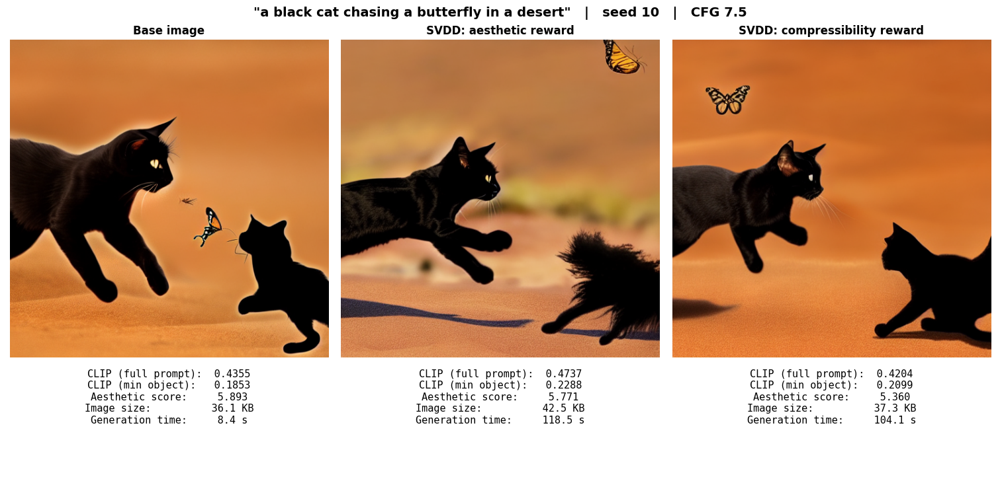

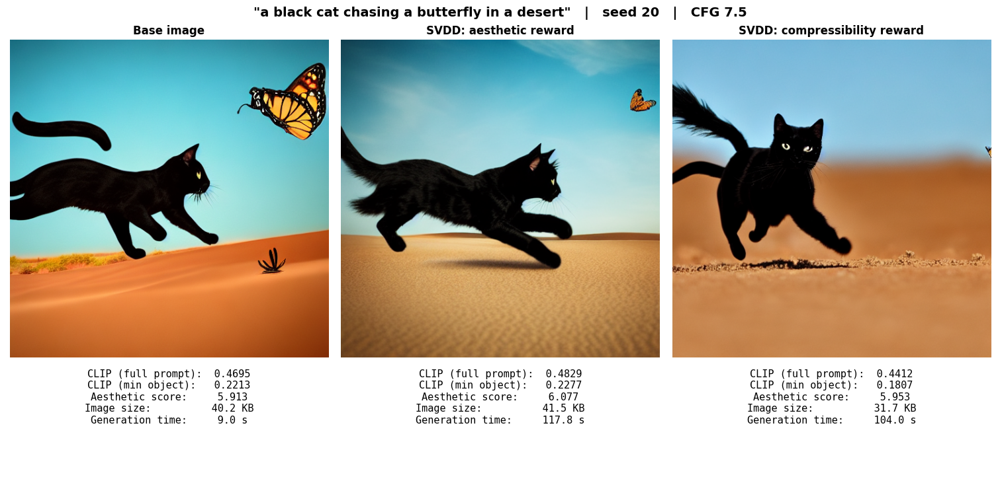

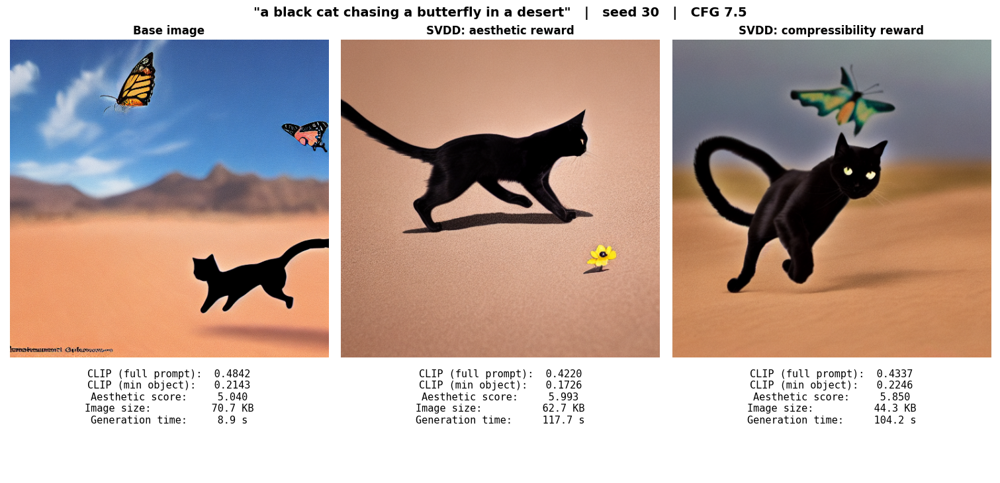

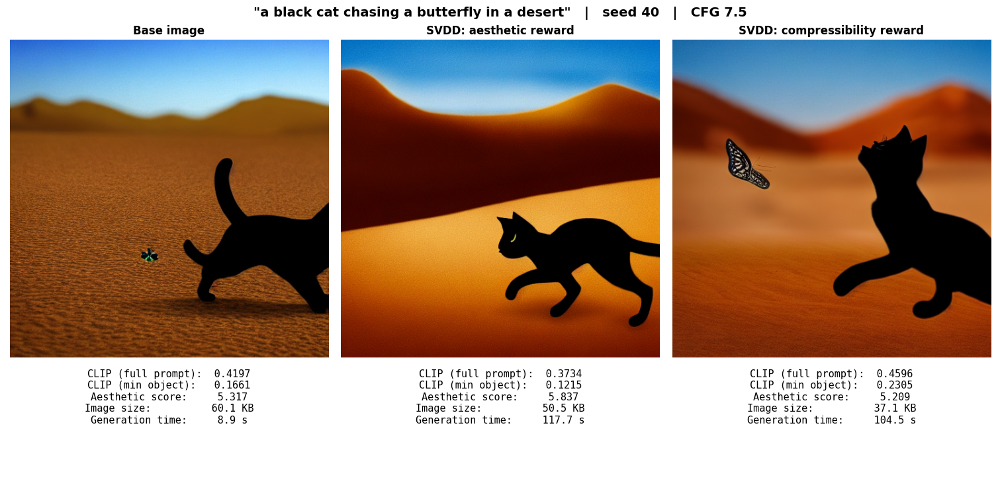

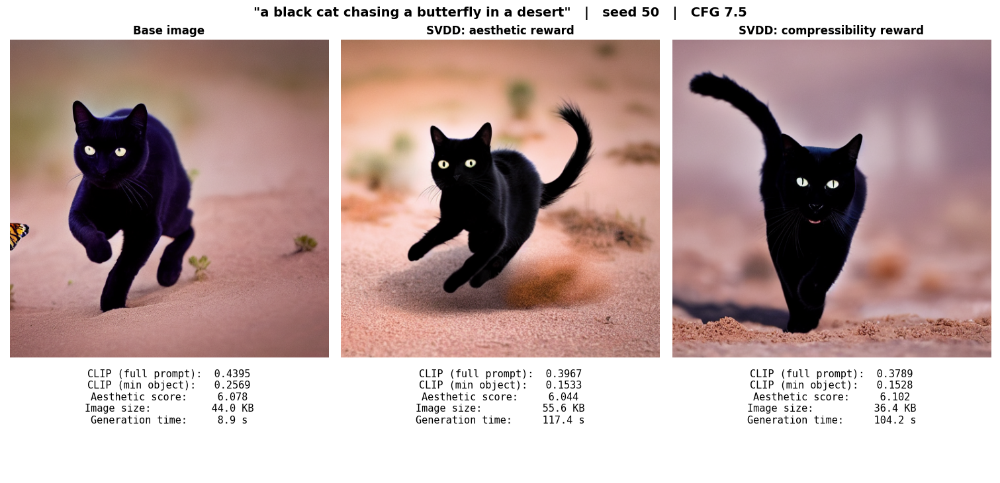

...

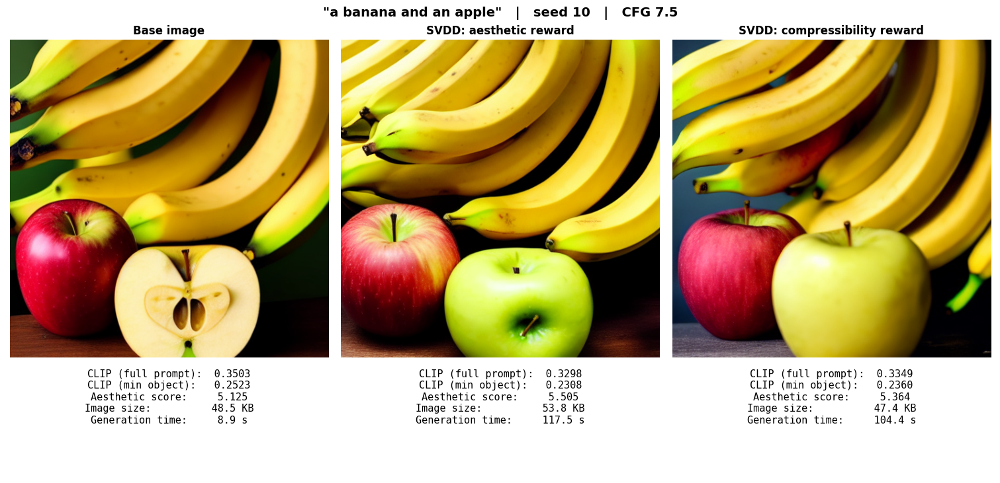

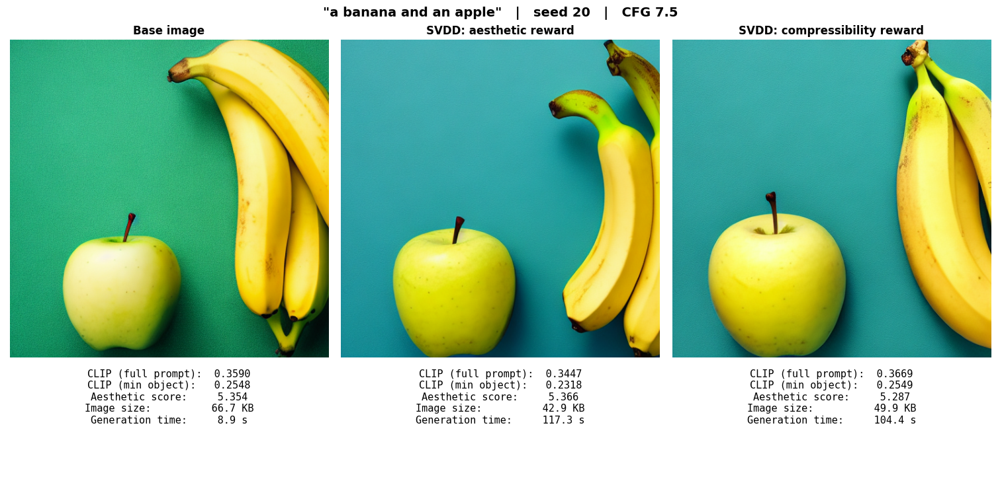

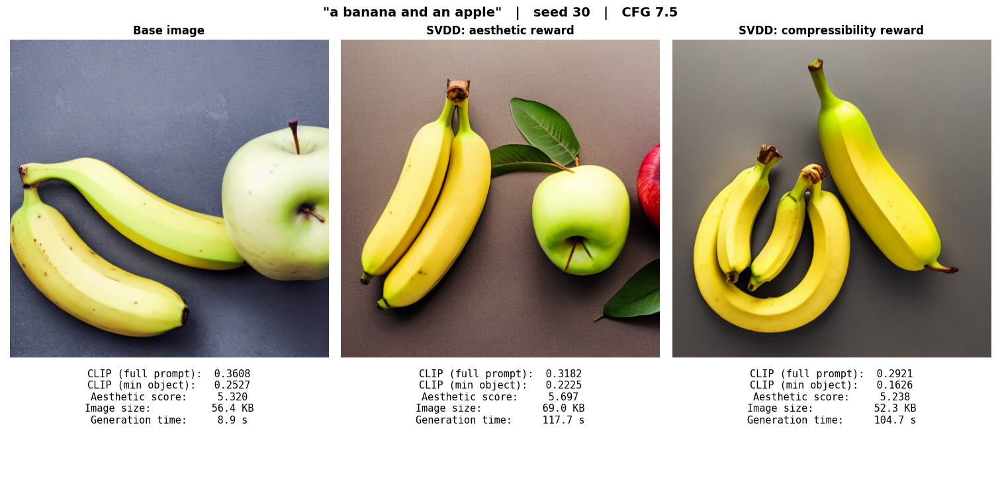

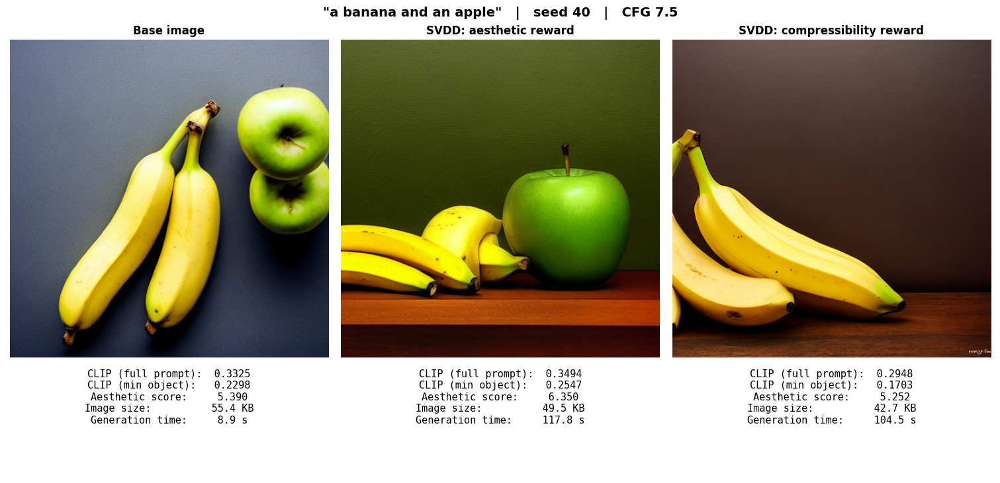

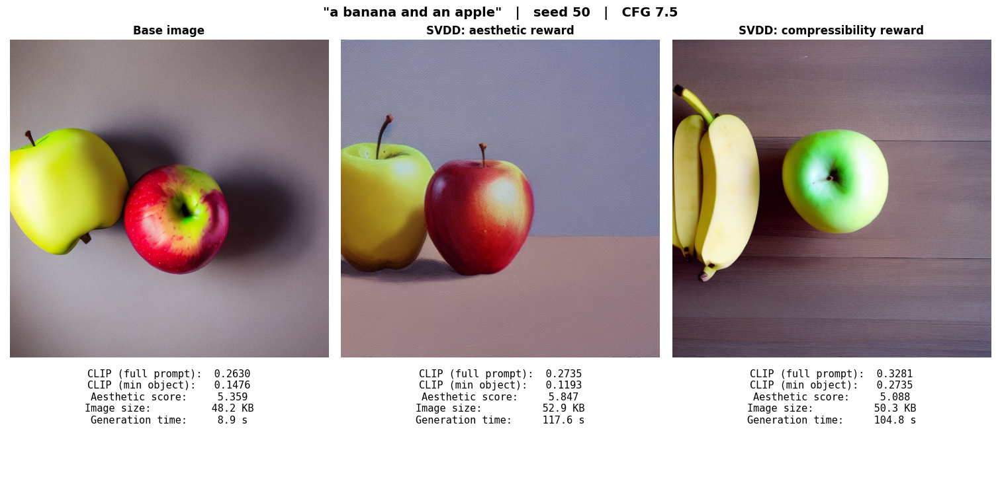

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from PIL import Image
from IPython.display import display

pd.set_option("display.width", 200, "display.max_columns", None)

ORDER = ["baseline", "svdd_aesthetic", "svdd_compress"]
NAMES = {"baseline": "Baseline",
         "svdd_aesthetic": "SVDD (aesthetic)",
         "svdd_compress": "SVDD (compress)"}

# ---------- 0. Merge scores with generation time + JPEG size from results_raw.csv ----------
raw = pd.read_csv(RES / "tables" / "results_raw.csv")
data = scores.merge(
    raw[["prompt", "cfg", "seed", "method", "seconds", "jpeg_kb"]],
    on=["prompt", "cfg", "seed", "method"], how="left")
data["method"] = pd.Categorical(data["method"], categories=ORDER, ordered=True)

COLS = {"clip_full_prompt": "CLIP (full prompt)",
        "clip_min_object":  "CLIP (min object)",
        "aesthetic_score":  "Aesthetic score",
        "jpeg_kb":          "Image size (KB)",
        "seconds":          "Gen. time (s)"}

# ---------- 1. Table: per seed, then average over all seeds ----------
per_seed = (data.groupby(["seed", "method"], observed=True)[list(COLS)]
                .mean().reset_index())
per_seed["Seed"] = per_seed["seed"].astype(str)

overall = data.groupby("method", observed=True)[list(COLS)].mean().reset_index()
overall["Seed"] = "Average (all seeds)"

table = pd.concat([per_seed.drop(columns="seed"), overall], ignore_index=True)
table["Model"] = table["method"].map(NAMES)
table = table[["Seed", "Model", *COLS]].rename(columns=COLS)

print("=== Summary: per seed (mean over prompts) and average over all seeds ===")
display(table.style.hide(axis="index")
        .format({"CLIP (full prompt)": "{:.4f}", "CLIP (min object)": "{:.4f}",
                 "Aesthetic score": "{:.3f}", "Image size (KB)": "{:.1f}",
                 "Gen. time (s)": "{:.1f}"}))
table.round(4).to_csv(RES / "tables" / "summary_per_seed_and_overall.csv", index=False)

# ---------- 2. Clean image comparison: 3 images + a text block under each ----------
FIG_DIR = RES / "figures" / "comparisons"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TITLES = {"baseline": "Base image",
          "svdd_aesthetic": "SVDD: aesthetic reward",
          "svdd_compress": "SVDD: compressibility reward"}

def show_comparison(prompt_key, cfg, seed, save=True):
    sub = data[(data.prompt == prompt_key) & (data.cfg == cfg) & (data.seed == seed)]
    full_prompt = sub.full_prompt.iloc[0]

    fig = plt.figure(figsize=(15, 7.2), constrained_layout=True)
    gs = GridSpec(2, 3, figure=fig, height_ratios=[4.5, 1.6])
    fig.suptitle(f'"{full_prompt}"   |   seed {seed}   |   CFG {cfg}',
                 fontsize=14, fontweight="bold")

    for j, method in enumerate(ORDER):
        r = sub[sub.method == method].iloc[0]

        ax_img = fig.add_subplot(gs[0, j])
        ax_img.imshow(Image.open(r.image_path))
        ax_img.set_title(TITLES[method], fontsize=12, fontweight="bold", pad=6)
        ax_img.axis("off")

        ax_txt = fig.add_subplot(gs[1, j])
        ax_txt.axis("off")
        ax_txt.text(
            0.5, 0.95,
            f"CLIP (full prompt):  {r.clip_full_prompt:.4f}\n"
            f"CLIP (min object):   {r.clip_min_object:.4f}\n"
            f"Aesthetic score:     {r.aesthetic_score:.3f}\n"
            f"Image size:          {r.jpeg_kb:.1f} KB\n"
            f"Generation time:     {r.seconds:.1f} s",
            ha="center", va="top", fontsize=11, family="monospace",
            transform=ax_txt.transAxes)

    if save:
        fig.savefig(FIG_DIR / f"{prompt_key}_cfg{cfg}_seed{seed}.png",
                    dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

for e in PROMPTS:
    for g in SCALES:
        for s in SEEDS:
            show_comparison(e["key"], g, s)

In [26]:
import shutil
shutil.make_archive("/kaggle/working/results", "zip", "/kaggle/working", "results")

'/kaggle/working/results.zip'